# Movie recommendations: what should this user watch next?

**Goal.** Given everything a user has rated so far, recommend 10 movies they haven't seen and will like. Success means the movies they go on to rate 4 stars or higher show up in that top 10.

**Data.** MovieLens (ml-latest-small): 100,836 ratings from 610 users on 9,724 movies, 1996–2018.

**Approach.** Four recommenders, from a "most popular" baseline to EASE, a linear autoencoder that is a strong performer in recent benchmarks. Each is tuned on a validation split and evaluated once on a held-out test set. Evaluation uses ranking metrics (precision, recall, NDCG at 10), coverage, and popularity bias.

**Result summary** is in section 7.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recsys import (temporal_split, Index, Popularity, ItemKNN, PureSVD, EASE,
                    recommend, ranking_metrics, relevant_sets, unseen_share)

pd.set_option("display.width", 160)
INK, INK_2, GRID, CONTEXT = "#0b0b0b", "#52514e", "#e4e3df", "#c3c2bd"
MODEL_COLORS = {"Most popular": CONTEXT, "PureSVD": "#2a78d6", "Item-kNN": "#eb6834", "EASE": "#1baf7a"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})
FIG_DIR = "../reports/figures"
K = 10

## 1. The data

In [2]:
ratings = pd.read_csv("../data/ml-latest-small/ratings.csv")
movies = pd.read_csv("../data/ml-latest-small/movies.csv").set_index("movieId")
n_users, n_movies = ratings["userId"].nunique(), ratings["movieId"].nunique()

print(f"{len(ratings):,} ratings | {n_users} users | {n_movies:,} movies")
print(f"Missing values: {ratings.isna().sum().sum()} | duplicate user-movie pairs: {ratings.duplicated(['userId', 'movieId']).sum()}")
print(f"Matrix density: {len(ratings) / (n_users * n_movies):.2%} of user-movie pairs have a rating")
print(f"Ratings of 4 or more: {(ratings['rating'] >= 4).mean():.0%}")
per_user = ratings.groupby("userId").size()
print(f"Ratings per user: min {per_user.min()}, median {per_user.median():.0f}, max {per_user.max():,}")

100,836 ratings | 610 users | 9,724 movies
Missing values: 0 | duplicate user-movie pairs: 0
Matrix density: 1.70% of user-movie pairs have a rating
Ratings of 4 or more: 48%
Ratings per user: min 20, median 70, max 2,698


The top 1% of movies (97) receive 16% of all ratings.
Half of all ratings go to the top 659 movies (6.8%).
3,446 movies (35%) have only one rating.


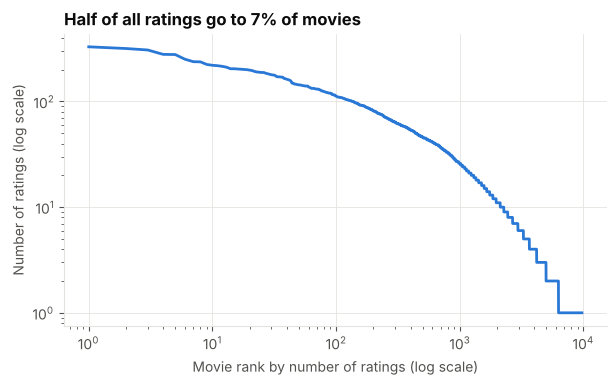

In [3]:
per_movie = ratings.groupby("movieId").size().sort_values(ascending=False)
share = per_movie.cumsum() / per_movie.sum()
top_1pct = int(len(per_movie) * 0.01)
print(f"The top 1% of movies ({top_1pct}) receive {share.iloc[top_1pct - 1]:.0%} of all ratings.")
print(f"Half of all ratings go to the top {(share < 0.5).sum() + 1:,} movies ({((share < 0.5).sum() + 1) / len(per_movie):.1%}).")
print(f"{(per_movie == 1).sum():,} movies ({(per_movie == 1).mean():.0%}) have only one rating.")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(1, len(per_movie) + 1), per_movie.values, color="#2a78d6", lw=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Movie rank by number of ratings (log scale)")
ax.set_ylabel("Number of ratings (log scale)")
ax.set_title("Half of all ratings go to 7% of movies", loc="left")
fig.savefig(f"{FIG_DIR}/long_tail.png")
plt.show()

This long tail is the core difficulty in recommendation. Popular movies are easy to recommend and often right, but useless for discovery. Most movies have too few ratings to learn much about. A good recommender has to beat "just show the hits" while still recommending a reasonable spread of the catalog.

## 2. Evaluation setup

**Time-based split.** For each user, their most recent 20% of ratings form the **test** set. Of what's left, the most recent 20% form a **validation** set for tuning. This mirrors the real task: predict what someone watches *next* from their history. A random split would let the model learn from a user's future.

**What counts as a hit.** A held-out movie the user rated **4 stars or higher**. The model sees a top-10 list per user, never including movies already rated.

**Metrics (at 10):**
- **Precision@10:** share of the 10 recommendations that were hits.
- **Recall@10:** share of the user's hits that made the list.
- **NDCG@10:** like recall, but rewards putting hits near the top. This is the main metric for model selection.
- **Hit rate@10:** share of users with at least one hit.
- **Coverage:** share of the catalog recommended to at least one user (a measure of variety).

**Candidate movies.** Models only recommend movies with at least 3 ratings in the training data. Movies seen once or twice carry almost no signal, and the restriction keeps item-to-item matrices small.

In [4]:
trainval, test = temporal_split(ratings, test_frac=0.2)
train, val = temporal_split(trainval, test_frac=0.2)
print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,} ratings")

def make_index(history, min_count=3):
    counts = history["movieId"].value_counts()
    return Index(ratings["userId"], counts[counts >= min_count].index)

val_index = make_index(train)
val_rel = relevant_sets(val_index, val)
print(f"Candidate movies for validation: {len(val_index.items):,}")
print(f"Validation users with at least one 4+ rating: {sum(bool(s) for s in val_rel)} of {n_users}")
print(f"Validation 4+ ratings on movies outside the candidate set: {unseen_share(val_index, val):.1%} (no model can recommend these)")

train 64,960 | validation 15,936 | test 19,940 ratings
Candidate movies for validation: 3,575
Validation users with at least one 4+ rating: 577 of 610
Validation 4+ ratings on movies outside the candidate set: 13.1% (no model can recommend these)


## 3. The four recommenders

| Model | Idea |
|---|---|
| **Most popular** | Recommend the most-liked movies to everyone. Not personalized; the baseline to beat. |
| **Item-kNN** | "People who liked X also liked Y": cosine similarity between movies, using each movie's *k* most similar neighbors. |
| **PureSVD** | Matrix factorization: compress the user–movie matrix into *f* hidden "taste" dimensions with a truncated SVD. |
| **EASE** | A linear model that predicts each movie from all the others (closed-form ridge regression with *λ* regularization), with the rule that a movie can't predict itself. |

Each model also chooses its **input**: every movie the user rated, or only the ones rated 4+. That's treated as one more setting to tune.

In [5]:
grid = (
    [("Most popular", Popularity, {})]
    + [("Item-kNN", ItemKNN, {"k": k}) for k in (25, 50, 100, 200, 400)]
    + [("PureSVD", PureSVD, {"factors": f}) for f in (10, 20, 50, 100, 200)]
    + [("EASE", EASE, {"lam": lam}) for lam in (50, 100, 200, 500, 1000, 2000)]
)
seen_val = val_index.matrix(train)
inputs = {"all ratings": None, "4+ only": 4.0}

rows = []
for input_name, min_rating in inputs.items():
    X = val_index.matrix(train, min_rating=min_rating)
    for name, cls, params in grid:
        model = cls(**params).fit(X)
        res = ranking_metrics(recommend(model, X, seen_val, K), val_rel, X.shape[1], K)
        rows.append({"model": name, "input": input_name, "params": str(params or "-"),
                     "NDCG@10": res["NDCG@10"], "recall@10": res["recall@10"]})
tuning = pd.DataFrame(rows)
best = tuning.loc[tuning.groupby("model")["NDCG@10"].idxmax()].sort_values("NDCG@10", ascending=False)
best.style.format({"NDCG@10": "{:.4f}", "recall@10": "{:.4f}"}).hide(axis="index")

model,input,params,NDCG@10,recall@10
EASE,4+ only,{'lam': 100},0.1369,0.1268
PureSVD,4+ only,{'factors': 20},0.1296,0.1271
Item-kNN,4+ only,{'k': 100},0.1289,0.1268
Most popular,4+ only,-,0.0791,0.0739


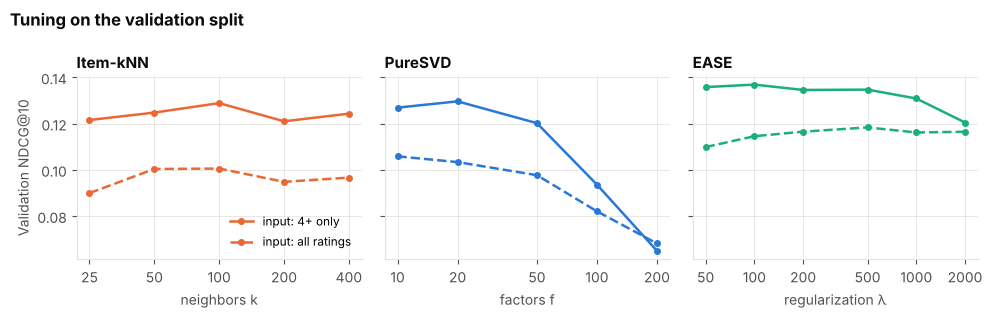

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), sharey=True)
for ax, (name, key) in zip(axes, [("Item-kNN", "k"), ("PureSVD", "factors"), ("EASE", "lam")]):
    for input_name, style in [("4+ only", "-"), ("all ratings", "--")]:
        t = tuning[(tuning["model"] == name) & (tuning["input"] == input_name)]
        xs = [eval(p)[key] for p in t["params"]]
        ax.plot(xs, t["NDCG@10"], style, color=MODEL_COLORS[name], marker="o", ms=4, lw=1.8,
                label=f"input: {input_name}")
    ax.set_xscale("log")
    ax.set_xticks(xs, [str(x) for x in xs])
    ax.minorticks_off()
    ax.set_title(name, loc="left", fontsize=11)
    ax.set_xlabel({"k": "neighbors k", "factors": "factors f", "lam": "regularization λ"}[key])
axes[0].set_ylabel("Validation NDCG@10")
axes[0].legend(loc="lower right", fontsize=8.5)
fig.suptitle("Tuning on the validation split", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/tuning.png")
plt.show()

Training on **4+ ratings only** works better for every personalized model: low ratings say a user watched a movie, but not that they liked it.

## 4. Final evaluation on the test set

Each model is refit with its best settings on train + validation (all history before the test period) and scored **once** on the test set.

To check that differences aren't luck, a **paired bootstrap over users** resamples users 2,000 times and recomputes the NDCG difference between two models on the same users.

In [7]:
test_index = make_index(trainval)
test_rel = relevant_sets(test_index, test)
seen_test = test_index.matrix(trainval)
print(f"Candidate movies: {len(test_index.items):,}")
print(f"Test 4+ ratings on movies outside the candidate set: {unseen_share(test_index, test):.1%}")

classes = {"Most popular": Popularity, "Item-kNN": ItemKNN, "PureSVD": PureSVD, "EASE": EASE}
final, recs_by_model, item_pop = {}, {}, None
for _, b in best.iterrows():
    params = eval(b["params"]) if b["params"] != "-" else {}
    X = test_index.matrix(trainval, min_rating=inputs[b["input"]])
    model = classes[b["model"]](**params).fit(X)
    recs = recommend(model, X, seen_test, K)
    final[b["model"]] = ranking_metrics(recs, test_rel, X.shape[1], K)
    recs_by_model[b["model"]] = (model, recs, X)

item_pop = np.asarray(seen_test.sum(axis=0)).ravel()  # training ratings per candidate movie
results = pd.DataFrame({m: {k: v for k, v in r.items() if not k.startswith("_")} for m, r in final.items()}).T
results["avg popularity of recs"] = [item_pop[recs_by_model[m][1]].mean() for m in results.index]
results = results.sort_values("NDCG@10", ascending=False)
results.style.format({"precision@10": "{:.3f}", "recall@10": "{:.3f}", "NDCG@10": "{:.3f}",
                      "hit rate@10": "{:.1%}", "coverage": "{:.1%}", "users evaluated": "{:.0f}",
                      "avg popularity of recs": "{:.0f}"})

Candidate movies: 4,190
Test 4+ ratings on movies outside the candidate set: 14.3%


,precision@10,recall@10,NDCG@10,hit rate@10,coverage,users evaluated,avg popularity of recs
EASE,0.098,0.102,0.125,49.6%,12.1%,587,137
PureSVD,0.090,0.096,0.119,48.4%,10.7%,587,142
Item-kNN,0.091,0.094,0.115,46.2%,13.3%,587,135
Most popular,0.060,0.053,0.079,32.2%,2.2%,587,212


In [8]:
def paired_bootstrap(a, b, n_boot=2000, seed=0):
    mask = ~np.isnan(a) & ~np.isnan(b)
    diff = a[mask] - b[mask]
    rng = np.random.default_rng(seed)
    boots = rng.choice(diff, size=(n_boot, len(diff)), replace=True).mean(axis=1)
    return diff.mean(), *np.percentile(boots, [2.5, 97.5])

order = list(results.index)
best_model = order[0]
print(f"NDCG@10 difference, {best_model} minus each other model (95% bootstrap CI):")
for other in order[1:]:
    d, lo, hi = paired_bootstrap(final[best_model]["_per_user_ndcg"], final[other]["_per_user_ndcg"])
    verdict = "significant" if lo > 0 else "not significant"
    print(f"  vs {other:13s} {d:+.4f}  [{lo:+.4f}, {hi:+.4f}]  {verdict}")
pop_ndcg = final["Most popular"]["NDCG@10"]
print(f"\n{best_model} NDCG@10 is {final[best_model]['NDCG@10'] / pop_ndcg:.2f}x the popularity baseline.")

NDCG@10 difference, EASE minus each other model (95% bootstrap CI):
  vs PureSVD       +0.0060  [-0.0019, +0.0135]  not significant
  vs Item-kNN      +0.0101  [+0.0030, +0.0176]  significant
  vs Most popular  +0.0459  [+0.0338, +0.0582]  significant

EASE NDCG@10 is 1.58x the popularity baseline.


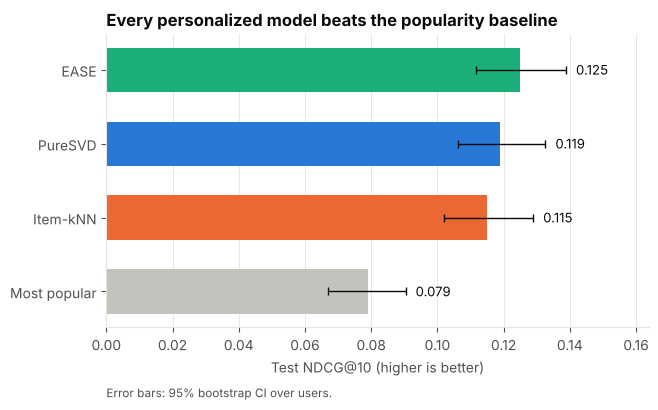

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.8))
res_sorted = results.sort_values("NDCG@10")
cis = []
for m in res_sorted.index:
    per = final[m]["_per_user_ndcg"]; per = per[~np.isnan(per)]
    boots = np.random.default_rng(1).choice(per, size=(2000, len(per))).mean(axis=1)
    cis.append(np.percentile(boots, [2.5, 97.5]))
cis = np.array(cis)
vals = res_sorted["NDCG@10"].to_numpy()
ax.barh(res_sorted.index, vals, color=[MODEL_COLORS[m] for m in res_sorted.index], height=0.6)
ax.errorbar(vals, res_sorted.index, xerr=[vals - cis[:, 0], cis[:, 1] - vals], fmt="none", ecolor=INK, capsize=3, lw=1)
for y, (v, hi) in enumerate(zip(vals, cis[:, 1])):
    ax.text(hi + 0.003, y, f"{v:.3f}", va="center", color=INK, fontsize=9.5)
ax.set_xlabel("Test NDCG@10 (higher is better)")
ax.set_xlim(0, max(cis[:, 1]) * 1.18)
ax.grid(axis="y", visible=False)
ax.set_title("Every personalized model beats the popularity baseline", loc="left")
ax.text(0, -0.24, "Error bars: 95% bootstrap CI over users.", transform=ax.transAxes, color=INK_2, fontsize=8.5)
fig.savefig(f"{FIG_DIR}/test_ndcg.png")
plt.show()

## 5. Beyond accuracy: variety and popularity bias

A recommender that only suggests blockbusters can score well and still be useless for discovery. Two checks:
- **Coverage:** how much of the catalog ever gets recommended.
- **Average popularity of recommended movies:** how many training ratings the recommended movies have, on average. Lower means more niche picks.

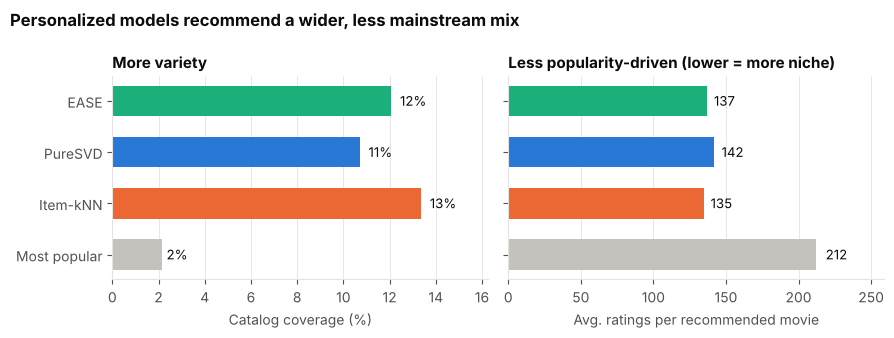

In [10]:
order_ = list(results.index)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
panels = [("coverage", "Catalog coverage (%)", lambda v: f"{v:.0%}", 100),
          ("avg popularity of recs", "Avg. ratings per recommended movie", lambda v: f"{v:.0f}", 1)]
for ax, (col, label, fmt, scale) in zip(axes, panels):
    vals = results.loc[order_, col].to_numpy()
    ax.barh(order_, vals * scale, color=[MODEL_COLORS[m] for m in order_], height=0.6)
    for y_, v in enumerate(vals):
        ax.text(v * scale * 1.02 + vals.max() * scale * 0.01, y_, fmt(v), va="center", color=INK, fontsize=9.5)
    ax.set_xlim(0, vals.max() * scale * 1.22)
    ax.set_xlabel(label)
    ax.grid(axis="y", visible=False)
axes[0].set_title("More variety", loc="left", fontsize=11)
axes[1].set_title("Less popularity-driven (lower = more niche)", loc="left", fontsize=11)
fig.suptitle("Personalized models recommend a wider, less mainstream mix", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/variety_and_popularity.png")
plt.show()

## 6. Who gets good recommendations?

Users with long histories give the model more to work with. Split users into thirds by how many movies they'd rated before the test period:

In [11]:
hist_len = trainval.groupby("userId").size().reindex(test_index.users).to_numpy()
bucket = pd.qcut(hist_len, 3, labels=["light", "medium", "heavy"])
edges = pd.Series(hist_len).groupby(bucket, observed=True).agg(["min", "max"])
seg = pd.DataFrame({m: pd.Series(final[m]["_per_user_ndcg"]).groupby(bucket, observed=True).mean()
                    for m in results.index})
seg.index = [f"{b} ({edges.loc[b, 'min']}–{edges.loc[b, 'max']} ratings)" for b in seg.index]
seg.style.format("{:.3f}")

,EASE,PureSVD,Item-kNN,Most popular
light (16–36 ratings),0.100,0.105,0.088,0.061
medium (37–102 ratings),0.112,0.096,0.103,0.064
heavy (103–2159 ratings),0.162,0.154,0.152,0.111


Every model does best for **heavy users**, who give it the most signal. For **light users** (16–36 ratings), PureSVD is slightly ahead of EASE. Its compact "taste" dimensions generalize better from a short history. A production system might switch models, or blend them, based on how much history a user has.

## 7. Example: recommendations for one user

What the best model recommends for a **typical user**: the user whose history length is closest to the median, rather than a hand-picked success story. Next to it are their recent highly rated movies; ✔ marks a recommendation they went on to rate 4+ in the test period.

In [12]:
model, recs, X = recs_by_model[best_model]
eligible = [(abs(n - np.median(hist_len)), uid) for n, uid, rel in zip(hist_len, test_index.users, test_rel) if rel]
uid = min(eligible)[1]
u = test_index.user_pos[uid]
history = trainval[(trainval["userId"] == uid) & (trainval["rating"] >= 4)].sort_values("timestamp")
print(f"User {uid}: {len(trainval[trainval['userId'] == uid])} ratings before the test period. Most recent 4+ ratings:")
for mid in history["movieId"].tail(8)[::-1]:
    print(f"   {movies.loc[mid, 'title']}")
print(f"\n{best_model} top 10:")
for j in recs[u]:
    mid = test_index.items[j]
    mark = "✔" if j in test_rel[u] else " "
    print(f" {mark} {movies.loc[mid, 'title']}  [{movies.loc[mid, 'genres'].replace('|', ', ')}]")
hits = sum(j in test_rel[u] for j in recs[u])
print(f"\n{hits} of 10 recommendations were movies this user later rated 4+ ({len(test_rel[u])} such movies in their test period).")

User 75: 56 ratings before the test period. Most recent 4+ ratings:
   Die Hard (1988)
   Blade Runner (1982)
   Star Wars: Episode IV - A New Hope (1977)
   Day the Earth Stood Still, The (1951)
   Lord of the Rings: The Two Towers, The (2002)
   Robin Hood (1973)
   Shrek 2 (2004)
   Shrek (2001)

EASE top 10:
 ✔ Star Wars: Episode V - The Empire Strikes Back (1980)  [Action, Adventure, Sci-Fi]
 ✔ Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)  [Action, Adventure]
   Star Wars: Episode VI - Return of the Jedi (1983)  [Action, Adventure, Sci-Fi]
 ✔ Indiana Jones and the Last Crusade (1989)  [Action, Adventure]
 ✔ Terminator, The (1984)  [Action, Sci-Fi, Thriller]
   Toy Story (1995)  [Adventure, Animation, Children, Comedy, Fantasy]
   Princess Bride, The (1987)  [Action, Adventure, Comedy, Fantasy, Romance]
   Rear Window (1954)  [Mystery, Thriller]
   Batman Begins (2005)  [Action, Crime, IMAX]
   Pirates of the Caribbean: The Curse of the Black Pearl

The recommendations clearly follow this user's taste for classic action, adventure and sci-fi. Four hits out of ten is **better than average**, though: precision@10 across all users is about 0.10, roughly one hit per list. That's normal for offline evaluation, where a "miss" often just means a movie the user never got around to rating.

## 8. Conclusions

- **Personalization pays off.** EASE, the best model, reaches a test NDCG@10 of 0.125, **1.58× the popularity baseline**. Half of users (49.6%) get at least one movie in their top 10 that they go on to rate 4+, versus 32% with the popular list.
- **EASE is the best overall, but its lead over PureSVD is within noise.** The paired bootstrap shows EASE significantly beats Item-kNN and the baseline, but not PureSVD. In an interview or a real team, that's a reason to pick on other grounds too: PureSVD is far cheaper to train and serve at scale, while EASE needs a full item-by-item matrix.
- **Train on what people liked.** Using only 4+ ratings as input beat using every rating, for every model.
- **Personalized models are less popularity-driven.** They recommend less popular movies (average 135–142 training ratings versus 212) and cover 5–6× more of the catalog.

## 9. Limitations and next steps

- **Offline is not online.** A movie the user didn't rate isn't necessarily one they'd dislike; they may never have seen it. Offline metrics understate real performance, and the real test is an A/B test on actual engagement.
- **Per-user time split.** Each user's test period comes after their own training data, but not after everyone else's, so models can see a little of the global "future". A global time cutoff would be stricter but leaves few users with test data in a dataset this small.
- **About 14% of test hits are unrecommendable** because they're new or rarely rated movies. Content features (genres, tags, descriptions) would help with this cold-start problem.
- **Small dataset.** 610 users is enough to compare methods but not to tune deep models. The same code runs on the 25-million-rating MovieLens release.